In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score
)
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
FILE_PATH = "Sales-[5444].csv"

In [2]:
# ---------------------------------------------------------------------
# 1. Load and inspect the dataset
# ---------------------------------------------------------------------
df = pd.read_csv(FILE_PATH)
print("Dataset shape:", df.shape)
print("\nColumns:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nSample records:\n", df.head())


Dataset shape: (1000, 10)

Columns:
 Item_Name             object
details               object
Catatory              object
price                float64
priceWithCurrency     object
available            float64
text                  object
sold                 float64
lastUpdated           object
itemLocation          object
dtype: object

Missing values:
 Item_Name              1
details                0
Catatory               3
price                  5
priceWithCurrency      1
available            111
text                   3
sold                   8
lastUpdated           53
itemLocation           0
dtype: int64

Sample records:
         Item_Name                                            details  \
0            Dior  Christian Dior Sauvage Men's EDP 3.4 oz Fragra...   
1         AS SHOW  A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...   
2       Unbranded                   HOGO BOSS cologne For Men 3.4 oz   
3  Giorgio Armani  Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau D...   


In [3]:
# ---------------------------------------------------------------------
# 2. Clean and engineer useful features
# ---------------------------------------------------------------------
data = df.copy()

# Convert numeric columns safely.
for col in ["price", "available", "sold"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Recover sold / available counts from the text column where possible.
# Examples: "8 available / 48 sold", "Last One / 6 sold".
if "text" in data.columns:
    text_col = data["text"].fillna("").astype(str)

    sold_from_text = text_col.str.extract(
        r"/\s*([\d,]+)\s*sold", flags=re.IGNORECASE
    )[0].str.replace(",", "", regex=False)
    available_from_text = text_col.str.extract(
        r"([\d,]+)\s*available", flags=re.IGNORECASE
    )[0].str.replace(",", "", regex=False)

    data["sold"] = data["sold"].fillna(
        pd.to_numeric(sold_from_text, errors="coerce")
    )
    data["available"] = data["available"].fillna(
        pd.to_numeric(available_from_text, errors="coerce")
    )

# Recover price from strings such as "US $84.99/ea".
if "priceWithCurrency" in data.columns:
    price_from_text = (
        data["priceWithCurrency"].fillna("").astype(str)
        .str.extract(r"([\d,]+\.?\d*)", expand=False)
        .str.replace(",", "", regex=False)
    )
    data["price"] = data["price"].fillna(
        pd.to_numeric(price_from_text, errors="coerce")
    )

# Parse update date and derive age relative to the newest recorded listing.
if "lastUpdated" in data.columns:
    data["lastUpdated"] = pd.to_datetime(
        data["lastUpdated"], errors="coerce", utc=True
    )
    newest_date = data["lastUpdated"].max()
    if pd.notna(newest_date):
        data["days_since_update"] = (
            newest_date - data["lastUpdated"]
        ).dt.total_seconds() / 86400
    else:
        data["days_since_update"] = np.nan
else:
    data["days_since_update"] = np.nan

# Treat obviously invalid values as missing.
for col in ["price", "available", "sold", "days_since_update"]:
    data.loc[data[col] < 0, col] = np.nan

# A logarithm reduces the influence of very large sales counts.
data["log_sold"] = np.log1p(data["sold"].clip(lower=0))
data["log_price"] = np.log1p(data["price"].clip(lower=0))

# Clean categorical text. Keep brand and product category, but avoid
# free-text description/location fields because they create sparse noise.
data["Item_Name"] = data["Item_Name"].fillna("Unknown").astype(str).str.strip()
data["Catatory"] = (
    data["Catatory"].fillna("Unknown").astype(str).str.strip().str.lower()
)
data.loc[data["Catatory"].isin(["", "/", "does not apply"]), "Catatory"] = "unknown"

numeric_features = [
    "log_price", "available", "log_sold", "days_since_update"
]
categorical_features = ["Item_Name", "Catatory"]


In [4]:
# ---------------------------------------------------------------------
# 3. Preprocess: impute, scale numeric values, encode categories
# ---------------------------------------------------------------------
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X = preprocessor.fit_transform(data[numeric_features + categorical_features])

# Use dense representation for PCA and clustering compatibility.
if hasattr(X, "toarray"):
    X = X.toarray()

print("\nPrepared feature matrix:", X.shape)


Prepared feature matrix: (1000, 302)



K-Means silhouette by k: [(2, np.float64(0.16138054528192367)), (3, np.float64(0.1571311467266007)), (4, np.float64(0.1826986932048505)), (5, np.float64(0.17084883731124192)), (6, np.float64(0.14399941928188995)), (7, np.float64(0.14788048771040777)), (8, np.float64(0.1348994801071))]
Selected K: 4


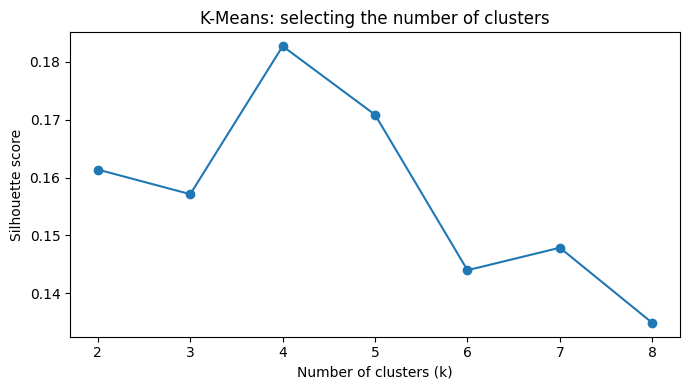

In [5]:
# ---------------------------------------------------------------------
# 4. Select K for K-Means using silhouette score
# ---------------------------------------------------------------------
k_results = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = model.fit_predict(X)
    if len(np.unique(labels)) > 1:
        k_results.append((k, silhouette_score(X, labels)))

best_k = max(k_results, key=lambda item: item[1])[0]
print("\nK-Means silhouette by k:", k_results)
print("Selected K:", best_k)

plt.figure(figsize=(7, 4))
plt.plot([x[0] for x in k_results], [x[1] for x in k_results], marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("K-Means: selecting the number of clusters")
plt.tight_layout()
plt.show()


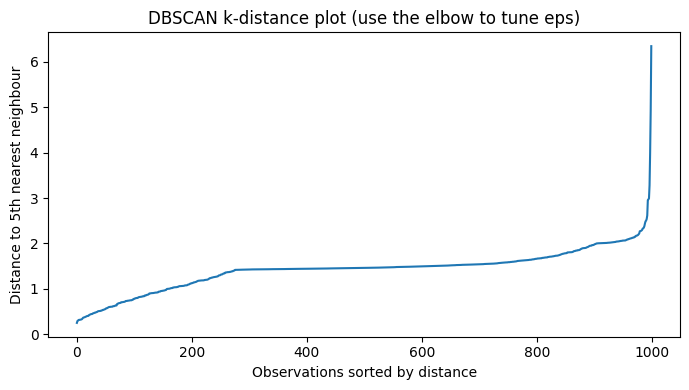

Initial DBSCAN eps: 1.969317471026637


In [6]:
# ---------------------------------------------------------------------
# 5. Fit K-Means, Hierarchical clustering and DBSCAN
# ---------------------------------------------------------------------
models = {}

kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=20)
models["K-Means"] = kmeans.fit_predict(X)

# Ward linkage is appropriate for Euclidean distances.
hierarchical = AgglomerativeClustering(
    n_clusters=best_k, linkage="ward"
)
models["Hierarchical"] = hierarchical.fit_predict(X)

# Estimate a DBSCAN eps value using the k-nearest-neighbour distance plot.
# min_samples is set to a modest value; tune eps after inspecting this plot.
min_samples = 5
neighbours = NearestNeighbors(n_neighbors=min_samples)
neighbours.fit(X)
distances, _ = neighbours.kneighbors(X)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(7, 4))
plt.plot(k_distances)
plt.xlabel("Observations sorted by distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbour")
plt.title("DBSCAN k-distance plot (use the elbow to tune eps)")
plt.tight_layout()
plt.show()

# Initial eps is the 90th percentile of the k-distance distribution.
# This is a starting point, not a guaranteed optimum.
dbscan_eps = float(np.percentile(k_distances, 90))
dbscan = DBSCAN(eps=dbscan_eps, min_samples=min_samples)
models["DBSCAN"] = dbscan.fit_predict(X)
print("Initial DBSCAN eps:", dbscan_eps)


In [7]:
# ---------------------------------------------------------------------
# 6. Evaluate clustering quality
# ---------------------------------------------------------------------
def evaluate_clustering(X_matrix, labels, model_name):
    labels = np.asarray(labels)
    # For DBSCAN, label -1 represents noise and is excluded from
    # internal cluster metrics. Require at least two non-noise clusters.
    mask = labels != -1
    valid_labels = labels[mask]
    unique_clusters = np.unique(valid_labels)

    result = {
        "Model": model_name,
        "Clusters (excluding noise)": len(unique_clusters),
        "Noise points": int(np.sum(labels == -1)),
        "Silhouette": np.nan,
        "Davies-Bouldin": np.nan,
        "Calinski-Harabasz": np.nan
    }

    if len(unique_clusters) >= 2 and mask.sum() > len(unique_clusters):
        X_valid = X_matrix[mask]
        result["Silhouette"] = silhouette_score(X_valid, valid_labels)
        result["Davies-Bouldin"] = davies_bouldin_score(X_valid, valid_labels)
        result["Calinski-Harabasz"] = calinski_harabasz_score(
            X_valid, valid_labels
        )
    return result

evaluation = pd.DataFrame([
    evaluate_clustering(X, labels, name)
    for name, labels in models.items()
])

print("\nModel evaluation:")
print(evaluation.to_string(index=False))


Model evaluation:
       Model  Clusters (excluding noise)  Noise points  Silhouette  Davies-Bouldin  Calinski-Harabasz
     K-Means                           4             0    0.182699        1.464099         212.445610
Hierarchical                           4             0    0.157714        1.469621         176.718846
      DBSCAN                           2            58    0.483030        0.631539          23.440907



PCA explained variance ratio: [0.25178382 0.18186014]
Total variance explained by 2 components: 0.43364395869713346


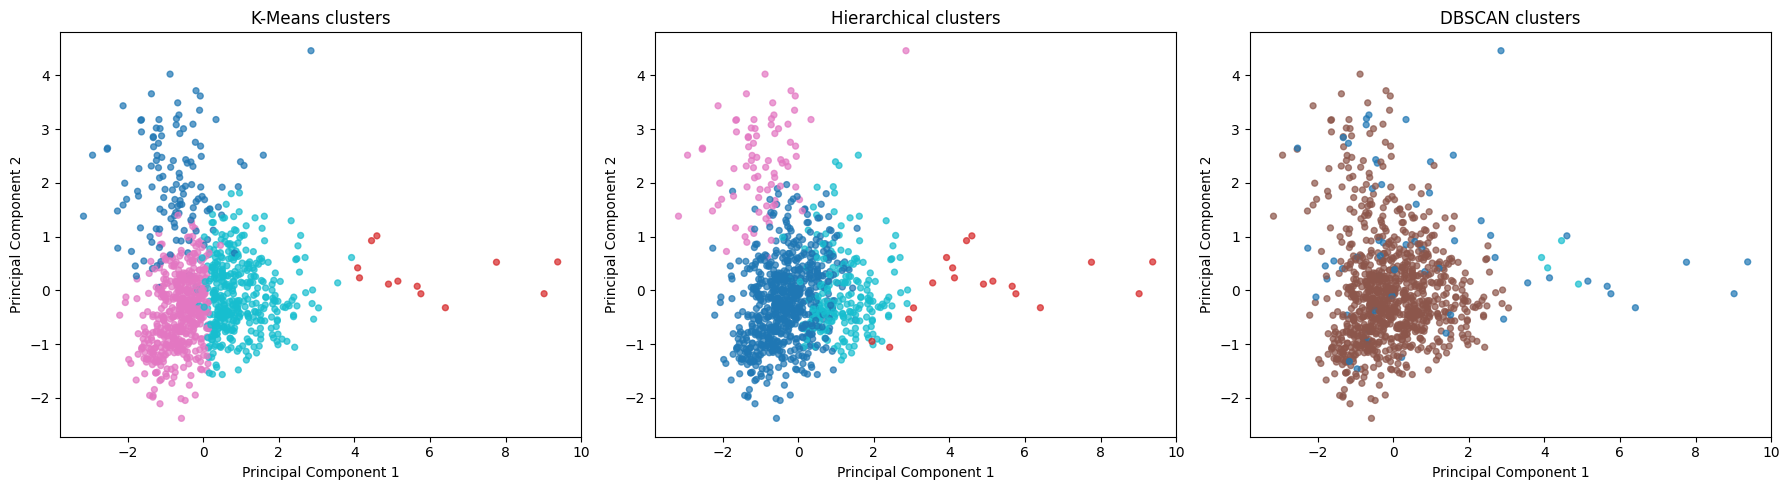

In [8]:
# ---------------------------------------------------------------------
# 7. PCA for two-dimensional visualisation
# ---------------------------------------------------------------------
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print("\nPCA explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained by 2 components:",
      pca.explained_variance_ratio_.sum())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, labels) in zip(axes, models.items()):
    scatter = ax.scatter(
        X_pca[:, 0], X_pca[:, 1],
        c=labels, cmap="tab10", s=18, alpha=0.7
    )
    ax.set_title(f"{name} clusters")
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

In [9]:
# ---------------------------------------------------------------------
# 8. Choose a final model (initially: best valid silhouette score)
# ---------------------------------------------------------------------
valid_eval = evaluation.dropna(subset=["Silhouette"]).copy()
if not valid_eval.empty:
    best_model_name = valid_eval.sort_values(
        "Silhouette", ascending=False
    ).iloc[0]["Model"]
    print("\nHighest silhouette model:", best_model_name)
else:
    best_model_name = "K-Means"
    print("\nNo model produced a valid silhouette score; using K-Means "
          "as a provisional model for inspection.")

data["cluster"] = models[best_model_name]



Highest silhouette model: DBSCAN



Cluster profile (original units):
        price                    available                     sold  \
        count       mean  median     count        mean median count   
cluster                                                               
-1         58  39.302931  23.765        54  110.425926   10.0    57   
 0        938  47.033454  36.430       831   12.909747   10.0   933   
 1          4  21.062500  20.630         4  282.500000  291.5     4   

                              
                mean  median  
cluster                       
-1       1248.491228   114.0  
 0        728.960343    48.0  
 1       4508.250000  4457.0  

Cluster -1:
Products: 58
Top categories:
 Catatory
eau de toilette    9
eau de cologne     7
perfume            5
body spray         4
cologne            3
Name: count, dtype: int64
Top brands:
 Item_Name
Ralph Lauren         3
Guy Laroche          2
Polo Ralph Lauren    2
Paul Sebastian       2
AXE                  2
Name: count, dtype: int64

Clus

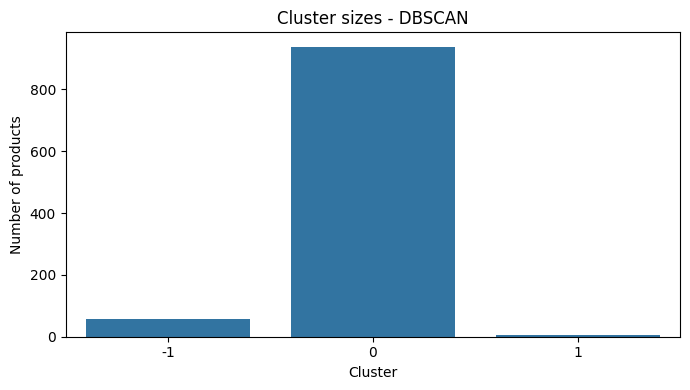

In [10]:
# ---------------------------------------------------------------------
# 9. Interpret the clusters in business terms
# ---------------------------------------------------------------------
# Use original units for interpretable summaries.
summary_columns = ["price", "available", "sold"]
cluster_summary = data.groupby("cluster")[summary_columns].agg(
    ["count", "mean", "median"]
)
print("\nCluster profile (original units):")
print(cluster_summary)

# Most common category and brand in each cluster.
for cluster_id, group in data.groupby("cluster"):
    print(f"\nCluster {cluster_id}:")
    print("Products:", len(group))
    print("Top categories:\n", group["Catatory"].value_counts().head(5))
    print("Top brands:\n", group["Item_Name"].value_counts().head(5))

# Visualise cluster sizes.
plt.figure(figsize=(7, 4))
sns.countplot(data=data, x="cluster", order=sorted(data["cluster"].unique()))
plt.title(f"Cluster sizes - {best_model_name}")
plt.xlabel("Cluster")
plt.ylabel("Number of products")
plt.tight_layout()
plt.show()
